In [3]:
import pandas as pd
import numpy as np
import lifelines as ll
import sksurv as sks
import matplotlib.pyplot as plt
# from bart_survival import surv_bart as sb


import lifelines as ll
from lifelines import KaplanMeierFitter
import subprocess
import threading as th
import multiprocessing as mp
import sys
sys.path.append("../src/")
# import sim_adj as sm
import arviz as az
# import brt_adj as sb

import random



In [2]:
def get_quant_events(qnt_t, event):
	q = np.array(qnt_t)
	et_ = event["t_event"].copy()
	et_out = event["t_event"].copy()
	es_out = event["status"].copy()
	for i in range(q.shape[0]):
		if i == 0:
			msk = et_<=q[i]
			et_out[msk] = q[i]
			# print(np.unique(et_out))
		else:
			msk = (q[i-1] < et_) & (et_ <= q[i])
			et_out[msk] = q[i]
			# print(np.unique(et_out))
			if i == q.shape[0]-1:
				msk = et_ > q[i]
				et_out[msk] = q[i]
				es_out[msk] = 0

	return {"t_event":et_out, "status":es_out}

def cox_ph_3_2(x_mat, event_dict, times, test):
    cph = ll.CoxPHFitter()
    q = np.hstack([event_dict["t_event"].reshape(-1,1),event_dict["status"].reshape(-1,1),x_mat]) 
    col = ["T", "E"] + [f"x_{i}" for i in range(x_mat.shape[1])] 
    q = pd.DataFrame(q, columns=col)

    cph.fit(q , "T", "E")
    cph_sv = cph.predict_survival_function(x_mat, times=times).to_numpy().T
    cph_sv_test = cph.predict_survival_function(test, times=times).to_numpy().T
    return cph_sv, cph_sv_test

def get_py_bart_surv3_2(x_mat, event_dict, model_dict, sampler_dict, test):
    trn = sb.get_surv_pre_train(y_time = event_dict["t_event"], y_status=event_dict["status"], x = x_mat, weight=None)
    post_test = sb.get_posterior_test(y_status=event_dict["status"], y_time=event_dict["t_event"], x=x_mat)



    BSM = sb.BartSurvModel(model_config=model_dict, sampler_config=sampler_dict)
    # fit with just the time column
    BSM.fit(y=trn["y"], X=trn["x"], weights=trn["w"], coords = trn["coord"], random_seed=99)
    # post1 = BSM.sample_posterior_predictive(X_pred=post_test["post_x"], coords=post_test["coords"])
    # sv_prob = sb.get_sv_prob(post1)
    # uniq_t = BSM.uniq_times

    # do test
    # post_test_test = sb.get_posterior_test(y_sk = , x_test = test) # old
    post_test_test = sb.get_posterior_test(y_status=event_dict["status"], y_time=event_dict["t_event"], x=test)
    post_test = BSM.sample_posterior_predictive(X_pred=post_test_test["post_x"], coords=post_test_test["coords"])
    sv_prob_test = sb.get_sv_prob(post_test)

    
    del BSM
    childs = mp.active_children()
    for child in childs:
        child.kill()
    # return sv_prob, sv_prob_test
    return sv_prob_test

# np.arange(11)
def save_to_csv(event_dict, x_mat, file="exp1_tmp.csv"):
    """helper function that passes the simulated event dataset to a csv
    - Used for R-bart

    Args:
        event_dict (_type_): _description_
        x_mat (_type_): _description_
        file (str, optional): _description_. Defaults to "exp1_tmp.csv".
    """
    col = ["t","s"] + ["x"+str(i) for i in range(x_mat.shape[1])]
    df = pd.DataFrame(np.hstack(
        [
            event_dict["t_event"],
            event_dict["status"],
            x_mat
        ]
    ),columns= col)
    exp_name = file
    path = f"../data/{exp_name}"
    with open(path, 'w') as f:
        df.to_csv(f, index=False)
    # df.to_csv(path,index = False)

def get_r_bart3_2(event_dict, x_mat, x_mat_tst, event_dict_tst):
    save_to_csv(event_dict, x_mat, file="exp3_tmp.csv")
    save_to_csv(event_dict_tst, x_mat_tst, file="exp3_tmp_tst.csv")
    
    subprocess.call("/usr/local/bin/Rscript --vanilla ../R/bart_3.R", shell=True)
    # with open("../data/exp3_tmp_out3.csv","r") as f:
        # r_sv = pd.read_csv(f).values
    r_sv = pd.read_csv("../data/exp3_tmp_out3_mu.csv").values
    r_sv_l = pd.read_csv("../data/exp3_tmp_out3_cil.csv").values
    r_sv_h = pd.read_csv("../data/exp3_tmp_out3_cih.csv").values

    r_sv_t = pd.read_csv("../data/exp3_tmp_out3_mu_t.csv").values
    r_sv_l_t = pd.read_csv("../data/exp3_tmp_out3_cil_t.csv").values
    r_sv_h_t = pd.read_csv("../data/exp3_tmp_out3_cih_t.csv").values

    return r_sv, r_sv_l, r_sv_h, r_sv_t, r_sv_l_t, r_sv_h_t

def rsqr(true, est):
    SSR = np.sum(np.power(true - est, 2))
    SST = np.sum(np.power(true - np.mean(true), 2))
    return 1-(SSR/SST)

def medabs(true, est):
    mab = np.median(np.abs(true-est))
    return mab

def rmse(true, est):
    # true = check_array(true)
    # est = check_array(est)
    out = np.sqrt(np.power((true - est),2).mean(0))
    return out

def bias(true, est):
    # true = check_array(true)
    # est = check_array(est)
    out = (true-est).mean(0)
    return out


In [ ]:

# comp 3
SPLIT_RULES3 =  [
    "pmb.ContinuousSplitRule()", # time
    "pmb.ContinuousSplitRule()", 
 	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
 	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()"
]
MODEL_DICT3 = {"trees": 100,
	"split_rules": SPLIT_RULES3
}
# SAMPLER_DICT3 = { # old
# 	"draws": 500,
# 	"tune": 100,
# 	"cores": 4,
# 	"chains": 4,
# 	"compute_convergence_checks": False
# }

SAMPLER_DICT3 = { # new
	"draws": 300,
	"tune": 50,
	"cores": 12,
	"chains": 12,
	"compute_convergence_checks": False
	# "pgbart":{
    #             "num_particles":5,
    #             "batch":(.5,.5)
    #         }
}

EXP_NAME = "cmplx_new"
RUN_NAME = "cmplx_1_400_200_2_test"
RUN_NAME_cmplx3 = "cmplx_3_400"

###########################
# ITERATIONS
ITERS = 200
SEED_ADDL=99
N = [400]
N_cmplx3 = [400, 1000, 4000]
ITERS_cmplx3 = 3
PLOT_ALL=True

complex_3 = {
    "type": "Complex, continuous, 20% cens",
    "x_vars": 10, 
    "VAR_CLASS": [1,1,1,1,1,1,1,1,1,1],
    # "VAR_CLASS": [2,2,2,2,2,2,2,2,2,2],
    "VAR_PROB":[None,None,None,None,None,None,None,None,None,None],
    # "VAR_PROB":[.5,.5,.5,.5,.5,.5,.5,.5,.5,.5],
    "scale_f" : "np.exp(3 + 0.5*np.sin(np.pi * x_mat[:,0] * x_mat[:,1]) + np.power((x_mat[:,2]-0.5), 2) + 0.5* x_mat[:,3] + 0.25 * x_mat[:,4])",
    # "scale_f": "20 + 5*(x_mat[:,0] + x_mat[:,1] + x_mat[:,2] + x_mat[:,3] + x_mat[:,4] + x_mat[:,5] + 10*x_mat[:,6])",
    "shape_f": "2",
    "cens_scale":3.7
}

In [45]:
print(np.exp(np.sin(3.14) * .5),np.exp(np.power(.5,2)),np.exp(.5),np.exp(.25))
print(np.exp(np.sin(3.14 * 0 * 0) * .5),np.exp(np.power(-.5,2)),np.exp(.5 * 0),np.exp(.25*0))
print(np.exp(np.sin(3.14 * .5 * .5) * .5),np.exp(np.power(-.5,2)),np.exp(.5 * 0),np.exp(.25*0))
print(np.exp(np.sin(3.14 * .25 * .75) * .5),np.exp(np.power(-.5,2)),np.exp(.5 * 0),np.exp(.25*0))

1.0007966436103375 1.2840254166877414 1.6487212707001282 1.2840254166877414
1.0 1.2840254166877414 1.0 1.0
1.4239185175809017 1.2840254166877414 1.0 1.0
1.320038570620867 1.2840254166877414 1.0 1.0


In [87]:
np.exp(.25 * .25)

1.0644944589178593

In [57]:
out = []
ii = []
jj = []

for i in [0,.1,.2,.3,.4,.5,.6,.7,.8,.9,1]:
    for j in [0,.1,.2,.3,.4,.5,.6,.7,.8,.9,1]:
        tmp = np.exp(np.sin(3.14 * i * j))
        out.append(tmp)
        ii.append(i)
        jj.append(j)


# [ii[i] for i,x in enumerate(out == max(out)) if x]
# j[out==max(out)]


In [75]:
f = pd.DataFrame([out, ii, jj]).T
f.columns =  ["out", "ii", "jj"]
f["comb"] = f.ii * f.jj
f["maxs"] = f.out.max()
f.loc[f.out == f.maxs]
f.loc[f.out < 2]


,out,ii,jj,comb,maxs
0,1.000000,0.0,0.0,0.0,2.718281
1,1.000000,0.0,0.1,0.0,2.718281
2,1.000000,0.0,0.2,0.0,2.718281
3,1.000000,0.0,0.3,0.0,2.718281
4,1.000000,0.0,0.4,0.0,2.718281
...,...,...,...,...,...
111,1.361879,1.0,0.1,0.1,2.718281
112,1.799534,1.0,0.2,0.2,2.718281
118,1.801853,1.0,0.8,0.8,2.718281
119,1.363943,1.0,0.9,0.9,2.718281


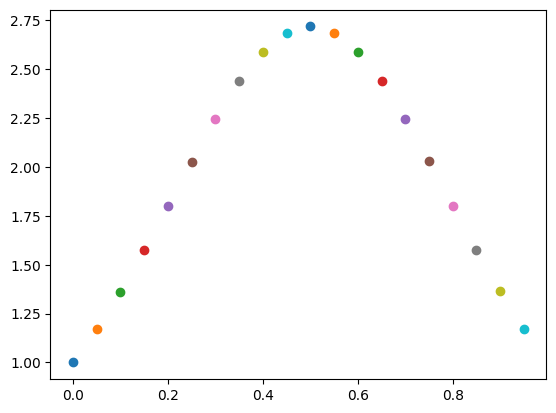

In [106]:
for i in np.arange(0,1,.05):
    # for j in np.arange(0,1, .05):
    t = np.exp(np.sin(i * 3.14))
    # t = i*j
    plt.plot(i,t, "o")

In [92]:
f[f.comb < .2]#.hist(bins=50)

,out,ii,jj,comb,maxs
0,1.000000,0.0,0.0,0.00,2.718281
1,1.000000,0.0,0.1,0.00,2.718281
2,1.000000,0.0,0.2,0.00,2.718281
3,1.000000,0.0,0.3,0.00,2.718281
4,1.000000,0.0,0.4,0.00,2.718281
...,...,...,...,...,...
99,1.000000,0.9,0.0,0.00,2.718281
100,1.321614,0.9,0.1,0.09,2.718281
101,1.708447,0.9,0.2,0.18,2.718281
110,1.000000,1.0,0.0,0.00,2.718281


In [5]:

def get_sim(rng, N, type, x_vars, VAR_CLASS, VAR_PROB, scale_f, shape_f, cens_scale):
    """Generates simulation dataest

    Args:
        rng (_type_): if int, generate new rng seeded as int value.
        N (_type_): _description_
        type (_type_): _description_
        x_vars (_type_): _description_
        VAR_CLASS (_type_): _description_
        VAR_PROB (_type_): _description_
        scale_f (_type_): _description_
        shape_f (_type_): _description_
        cens_scale (_type_): _description_

    Returns:
        _type_: _description_
    """
    x_mat = sm.get_x_matrix(
        N = N,
        x_vars = x_vars, 
        VAR_CLASS=VAR_CLASS,
        VAR_PROB= VAR_PROB,
        rng = rng
    )

    event_dict, sv_true, sv_scale_true = sm.simulate_survival(
        x_mat = x_mat,
        scale_f=scale_f,
        shape_f=shape_f,
        cens_scale=cens_scale,
        rng = rng
    )
    return type, x_mat, event_dict, sv_true, sv_scale_true



In [107]:
tmp = x_mat[:,0] * x_mat[:,1]
print(tmp.shape)
((tmp > .2) & (tmp < .8)).sum()

(800,)


358

mean shape 2.0
mean scale 42.12100038637298
178.0
mean time draws 36.733732766805936
cens mean 153.26875


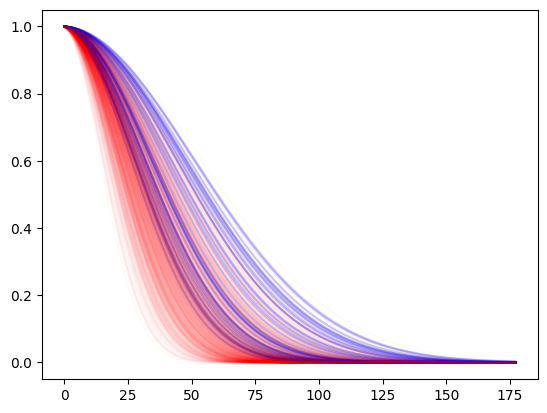

In [81]:
rng = np.random.default_rng()
N= 400
N_test = 400

scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, N + N_test, **complex_3)


sv = sv_true["sv_true"]
x_mat
for i in range(sv.shape[0]):
    # if (x_mat[i,0] > 0.5) & (x_mat[i,1] > 0.5):
    tmp = x_mat[i,0] * x_mat[i,1]
    if ((tmp > .45) & (tmp <= .55)):
        plt.plot(sv[i], color="blue", alpha=.2)
    else:
        plt.plot(sv[i], color="red", alpha=.02)

In [108]:


def big_loop(seed, N):
    N_test = 400

    # shuffle to cut
    go = True
    inflate = 100
    other_count = 0
    while go:
        tmp_seed = seed*inflate
        rng = np.random.default_rng(tmp_seed)
        scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, N + N_test, **complex_3)
        index =list(range(N + N_test))
        random.Random(tmp_seed).shuffle(index)

        event_dict_upt = {
            "t_event":event_dict["t_event"][index[:N]],
            "status": event_dict["status"][index[:N]],
        }
        x_mat_t = x_mat[index[N:],]
        qnt_t = np.ceil(np.quantile(range(int(event_dict_upt["t_event"].max())), [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1])).astype("int")
        # print(qnt_t)
        print(qnt_t.shape)
        print(qnt_t)

        event_dict2 = get_quant_events(qnt_t=qnt_t, event=event_dict_upt)
        # event_dict2_upt = {
        #     "t_event": event_dict2["t_event"][index[:N]],
        #     "status" : event_dict2["status"][index[:N]]
        # }
        event_dict2_upt = event_dict2
        print(event_dict2["t_event"].shape)
        print(np.unique(event_dict2["t_event"]).shape)
        print(np.unique(event_dict["t_event"]).shape)
        print(np.unique(event_dict2["t_event"]))
        event_dict2_upt_tst = {
            "t_event": event_dict["t_event"][index[N:],],
            "status": event_dict["status"][index[N:],]
        }
        # print(np.unique(event_dict2["t_event"]))

        # event_dict2["t_event"][index[N:],]e#subsetting
        # if np.all(qnt_t == np.unique(event_dict2["t_event"])):
        #     print("good sim")
        #     go = False
        #     print(tmp_seed)
        if qnt_t.shape[0] == np.unique(event_dict2_upt["t_event"]).shape[0]:
            print("match size")
            go = False
            print(tmp_seed)
        else:
            print("NO")
            go = True
        if other_count > 10:
            assert(False)
        inflate += 100
        other_count += 1


    cens_perc2 = event_dict2["status"][event_dict2["status"] == 0].shape[0]/event_dict2["status"].shape[0]        
    # print(cens_perc2)

    uniq_t = np.unique(event_dict["t_event"])
    # print(uniq_t)
    true_t = sv_true["true_times"]
    # true_t
    # event_dict2["status"][index[:N],][event_dict2["status"][index[:N],]==0].shape[0]/ 400



    # cox model
    cph_sv, cph_sv_test = cox_ph_3_2(x_mat[index[:N],], event_dict_upt, times=qnt_t, test = x_mat_t)
    # print(cph_sv.shape)
    # print(cph_sv_test.shape)

    # P-bart
    model_dict = MODEL_DICT3
    sampler_dict = SAMPLER_DICT3
    # pb_sv, pb_sv_test = get_py_bart_surv3_2(x_mat=x_mat[index[:N],:], event_dict=event_dict2_upt, model_dict=model_dict, sampler_dict=sampler_dict, test = x_mat_t)
    pb_sv_test = get_py_bart_surv3_2(x_mat=x_mat[index[:N],:], event_dict=event_dict2_upt, model_dict=model_dict, sampler_dict=sampler_dict, test = x_mat_t)
    # p_sv = pb_sv["sv"].mean(0)
    p_sv_test = pb_sv_test["sv"].mean(0)

    # r-BART
    r_sv, r_sv_l, r_sv_h, r_sv_t, r_sv_l_t, r_sv_h_t = get_r_bart3_2(
        event_dict2_upt, 
        x_mat=x_mat[index[:N],:], 
        x_mat_tst = x_mat[index[N:],:],
        event_dict_tst = event_dict2_upt_tst
    )


    # set up the times
    time_indx = [np.where(true_t == i)[0][0] for i in qnt_t]
    true_trn = sv_true["sv_true"][:, time_indx][index[:N],:]
    true_test = sv_true["sv_true"][:, time_indx][index[N:],:]
    # test plot


    ####### plot
    plt.close()
    diff1 = (true_test - p_sv_test)[:, 1:-1] #p 
    diff2 = (true_test - r_sv_t)[:,1:-1] # r
    diff3 = (true_test - cph_sv_test)[:, 1:-1]

    # np.quantile(diff, [0.25, 0.5, 0.75], axis=0)
    pst = (np.arange(9) + 1) * 3
    alpha2 = 0.8
    alpha3 = 0.2
    plt.boxplot(diff1, 
                positions = pst-.7,
                medianprops = {"color":"black", "alpha":alpha2},
                boxprops = {"alpha":alpha2},
                whiskerprops={"alpha":alpha2},
                capprops={"alpha":alpha2},
                flierprops={"alpha":alpha3}
                )
    alpha2 = 0.6
    plt.boxplot(diff2, 
                positions = (pst),
                medianprops = {"color":"black", "alpha":alpha2},
                    boxprops = {"alpha":alpha2},
                whiskerprops={"alpha":alpha2},
                capprops={"alpha":alpha2},
                flierprops={"alpha":alpha3}
                )
    alpha2 = 0.4
    plt.boxplot(diff3, 
                positions = (pst +.7),
                medianprops = {"color":"black", "alpha":alpha2},
                    boxprops = {"alpha":alpha2},
                whiskerprops={"alpha":alpha2},
                capprops={"alpha":alpha2},
                flierprops={"alpha":alpha3}
                )
    plt.axhline(y = 0, linestyle="dashed", color="black", alpha= 0.2)

    lbls = [str(i) for i in [0.1,.2, .3, .4, .5, .6,.7,.8, .9]]
    lbls = lbls[::-1]
    plt.xticks(
        np.hstack([pst-.7, pst, pst + .7]) ,
        # labels =  ["" + x for x in lbls] + ["R" + x for x in lbls]  + ["C" + x for x in lbls] ,
        labels = ["p-BART " + x for x in lbls] + ["r-BART " + x for x in lbls] + ["CPHM " + x for x in lbls],
        rotation = 90
    )

    plt.ylabel("True - Prediction (Survival Probability)")

    pth ="../final_figs/oos_seed"+str(seed)+ "_N_" +str(N)+".png"
    plt.savefig(pth)
    p_rmse = []
    r_rmse = []
    c_rmse = []


    p_rmse = []
    r_rmse = []
    c_rmse = []

    p_mabs = []
    r_mabs = []
    c_mabs = []

    p_rsq = []
    r_rsq = []
    c_rsq = []



    # res
    for i in range(true_test.shape[1]):
        p_rmse.append(rmse(true_test[:,i], p_sv_test[:,i]))
        r_rmse.append(rmse(true_test[:,i], r_sv_t[:,i]))
        c_rmse.append( rmse(true_test[:,i], cph_sv_test[:,i]))

        p_rmse.append(bias(true_test[:,i], p_sv_test[:,i]))
        r_bias.append(bias(true_test[:,i], r_sv_t[:,i]))
        c_bias.append(bias(true_test[:,i], cph_sv_test[:,i]))

        p_mabs.append(medabs(true_test[:,i], p_sv_test[:,i]))
        r_mabs.append(medabs(true_test[:,i], r_sv_t[:,i]))
        c_mabs.append(medabs(true_test[:,i], cph_sv_test[:,i]))

        p_rsq.append(rsqr(true_test[:,i], p_sv_test[:,i]))
        r_rsq.append(rsqr(true_test[:,i], r_sv_t[:,i]))
        c_rsq.append(rsqr(true_test[:,i], cph_sv_test[:,i]))

    deciles= [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1][::-1]
    itersss = np.repeat(tmp_seed, 11)
    nnn = np.repeat(N, 11)
    df_tst2 = pd.DataFrame([p_rmse, r_rmse, c_rmse, p_bias, r_bias, c_bias, p_mabs, 
                            r_mabs, c_mabs, p_rsq, r_rsq, c_rsq, deciles, itersss, nnn]).T

    df_tst2.columns = "p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n".split(",")
    df_tst2

    return(df_tst2)

mean shape 2.0
mean scale 42.69293178870243
196.0
mean time draws 38.15218730605267
cens mean 156.84954545454545
(11,)
[  9  18  35  53  70  88 105 123 140 158 175]
(4000, 1)
(11,)
(125,)
[  9.  18.  35.  53.  70.  88. 105. 123. 140. 158. 175.]
match size
1100


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 50 tune and 300 draw iterations (600 + 3_600 draws total) took 148 seconds.
Sampling: [f]


Output()

Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/notebook"
 num [1:4000, 1:10] 0.065 0.374 0.873 0.556 0.095 0.48 0.321 0.521 0.521 0.447 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:400, 1:10] 0.462 0.254 0.418 0.457 0.201 0.015 0.818 0.813 0.521 0.192 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 13131, 11, 44000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 9.000000, 0.918000
xp1,xp[np*p]: 9.000000, 0.918000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-0.692271
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 

NameError: name 'r_bias' is not defined

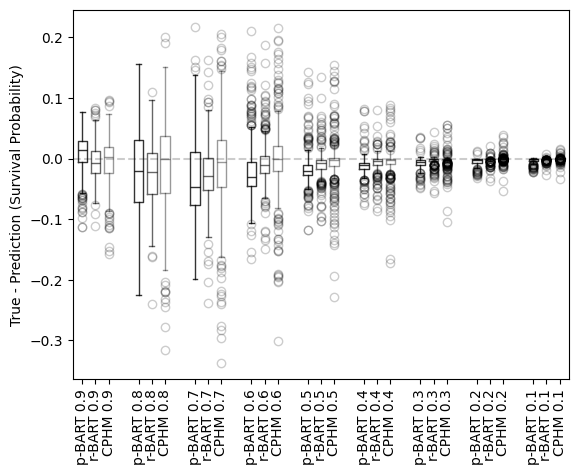

In [109]:
df_out = pd.DataFrame()
# for i in [11,22, 33,44,55,66,77,88,99,1010]:
for i in [11]:
    tmp_df = big_loop(seed = i, N=4000)
    df_out = pd.concat([df_out, tmp_df])

In [601]:
df_out.to_csv("../complex1_N_4000_2.csv")

In [602]:
df_out.groupby("deciles").mean().to_csv("../comple1_N_4000_2_mean.csv")

# for i in []

Text(0, 0.5, 'True - Prediction (Survival Probability)')

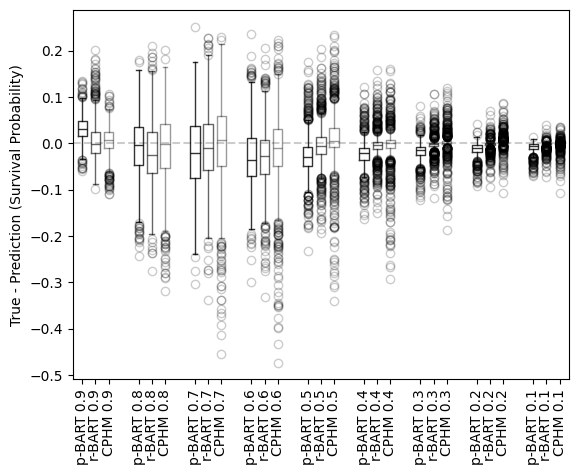

In [412]:
# diff1 = (true_trn - p_sv)[:, 1:-1] #p 
# diff2 = (true_trn - r_sv)[:,1:-1] # r
# diff3 = (true_trn - cph_sv)[:, 1:-1]

# # np.quantile(diff, [0.25, 0.5, 0.75], axis=0)
# pst = (np.arange(9) + 1) * 3
# alpha2 = 0.8
# alpha3 = 0.2
# plt.boxplot(diff1, 
#             positions = pst-.7,
#             medianprops = {"color":"black", "alpha":alpha2},
#             boxprops = {"alpha":alpha2},
# 			whiskerprops={"alpha":alpha2},
# 			capprops={"alpha":alpha2},
# 			flierprops={"alpha":alpha3},
#             # showfliers=False
#             )
# alpha2 = 0.6

# plt.boxplot(diff2, 
#             positions = (pst),
#             medianprops = {"color":"black", "alpha":alpha2},
#                 boxprops = {"alpha":alpha2},
# 			whiskerprops={"alpha":alpha2},
# 			capprops={"alpha":alpha2},
# 			flierprops={"alpha":alpha3}
#             )
# alpha2 = 0.4
# plt.boxplot(diff3, 
#             positions = (pst +.7),
#             medianprops = {"color":"black", "alpha":alpha2},
#                 boxprops = {"alpha":alpha2},
# 			whiskerprops={"alpha":alpha2},
# 			capprops={"alpha":alpha2},
# 			flierprops={"alpha":alpha3}
#             )
# plt.axhline(y = 0, linestyle="dashed", color="black", alpha= 0.2)

# lbls = [str(i) for i in [0.1,.2, .3, .4, .5, .6,.7,.8, .9]]
# lbls = lbls[::-1]
# plt.xticks(
# 	np.hstack([pst-.7, pst, pst + .7]) ,
# 	# labels =  ["" + x for x in lbls] + ["R" + x for x in lbls]  + ["C" + x for x in lbls] ,
#     labels = ["p-BART " + x for x in lbls] + ["r-BART " + x for x in lbls] + ["CPHM " + x for x in lbls],
# 	rotation = 90
# )

# plt.ylabel("True - Prediction (Survival Probability)")

In [2]:
n400 = pd.read_csv("../complex1_N_400.csv")
n1000 = pd.read_csv("../complex1_N_1000.csv")
# n4000 = pd.read_csv("../complex1_N_4000.csv")
n4000 = pd.read_csv("../complex1_N_4000_2.csv")

n400.groupby("deciles").mean().sort_values(by="deciles", ascending=False)
n400.groupby("deciles").std().sort_values(by="deciles", ascending=False)


,Unnamed: 0,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,seed,n
deciles,,,,,,,,,,,,,,,
1.00,0.0,0.006879,0.008481,0.005339,0.006499,0.007309,0.006326,0.005946,0.004154,0.003886,1.435075,2.022078,0.690371,94076.909435,0.0
0.90,0.0,0.012599,0.011328,0.008059,0.014018,0.008032,0.007664,0.010177,0.006112,0.004046,0.732217,0.384997,0.068557,94076.909435,0.0
0.80,0.0,0.011538,0.010712,0.013248,0.022594,0.022435,0.026258,0.008270,0.009112,0.009705,0.072378,0.127457,0.050510,94076.909435,0.0
0.70,0.0,0.010898,0.011512,0.010672,0.028030,0.027167,0.026374,0.007909,0.010627,0.012027,0.074973,0.096121,0.058691,94076.909435,0.0
0.60,0.0,0.011769,0.012536,0.011160,0.025278,0.024216,0.024444,0.011717,0.012598,0.012760,0.063405,0.043030,0.068447,94076.909435,0.0
0.50,0.0,0.013184,0.017437,0.014333,0.018374,0.015823,0.017144,0.012504,0.015510,0.012836,0.088182,0.074069,0.132546,94076.909435,0.0
0.40,0.0,0.013066,0.017696,0.012694,0.012321,0.008641,0.011039,0.011939,0.013737,0.010372,0.274499,0.201891,0.284967,94076.909435,0.0
0.30,0.0,0.011230,0.015912,0.013956,0.008744,0.007664,0.010297,0.009543,0.011842,0.008335,0.885718,0.568784,0.512217,94076.909435,0.0
0.20,0.0,0.009805,0.014144,0.018652,0.007577,0.008874,0.015590,0.008747,0.008732,0.007472,2.780523,1.736089,1.451508,94076.909435,0.0


In [3]:
m400 = pd.DataFrame(n400.groupby("deciles").mean().sort_values(by="deciles", ascending=False).loc[[.9,.7,.5,.3,.1]].mean(axis=0)).T
m400
m1000 = pd.DataFrame(n1000.groupby("deciles").mean().sort_values(by="deciles", ascending=False).loc[[.9,.7,.5,.3,.1]].mean(axis=0)).T
m4000 = pd.DataFrame(n4000.groupby("deciles").mean().sort_values(by="deciles", ascending=False).loc[[.9,.7,.5,.3,.1]].mean(axis=0)).T

# pd.concat([m400,m1000, m4000]).to_excel("../complex_res_mean.xlsx")

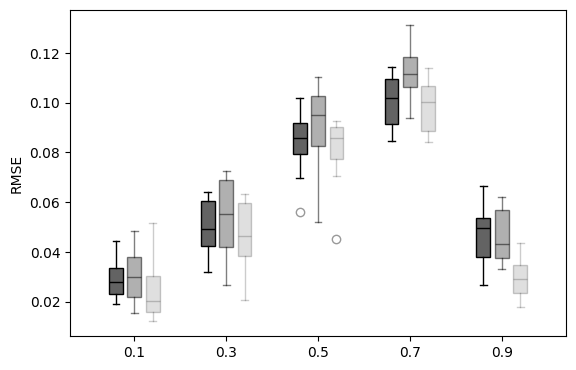

In [7]:
for i in [.9, .7, .5, .3, .1]:
    tmp = n400[n400["deciles"]== i]
# plt.boxplot(tmp)
    tmp_rmse = tmp[["p_rmse", "r_rmse", "c_rmse"]]
    # plt.boxplot(tmp_rmse)
    pst = i * 5
    alpha3 = 0.4
    alpha2=1
    plt.boxplot(
            tmp["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.5
    plt.boxplot(
            tmp["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.2
    plt.boxplot(
            tmp["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # lbls = [str(i) for i in [0.1,.2, .3, .4, .5, .6,.7,.8, .9]]
lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]
# pts = np.array([0.9, .7,  .5, .3, .1]) * 5
pts = np.array([0.1, .3,  .5, .7, .9]) * 5
# lbls = lbls[::-1]
plt.xticks(
    pts, lbls
    # np.hstack([pts-.2, pts, pts + .2]) ,
    # labels =  ["" + x for x in lbls] + ["R" + x for x in lbls]  + ["C" + x for x in lbls] ,
    # labels = ["p-BART " + x for x in lbls] + ["r-BART " + x for x in lbls] + ["CPHM " + x for x in lbls],
    # rotation = 90
)
plt.ylabel("RMSE")
plt.subplots_adjust(bottom=0.20)
plt.savefig("../final_figs/ooo_rmse_N_400.png")

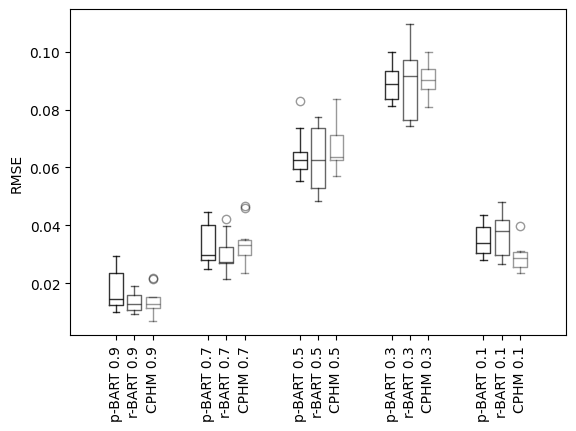

In [597]:
for i in [.9, .7, .5, .3, .1]:
    tmp = n1000[n1000["deciles"]== i]

    pst = i * 5
    alpha3 = 0.4
    alpha2=0.8
    plt.boxplot(
            tmp["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.6
    plt.boxplot(
            tmp["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.4
    plt.boxplot(
            tmp["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # lbls = [str(i) for i in [0.1,.2, .3, .4, .5, .6,.7,.8, .9]]
lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]
# pts = np.array([0.9, .7,  .5, .3, .1]) * 5
pts = np.array([0.1, .3,  .5, .7, .9]) * 5
lbls = lbls[::-1]
plt.xticks(
    np.hstack([pts-.2, pts, pts + .2]) ,
    # labels =  ["" + x for x in lbls] + ["R" + x for x in lbls]  + ["C" + x for x in lbls] ,
    labels = ["p-BART " + x for x in lbls] + ["r-BART " + x for x in lbls] + ["CPHM " + x for x in lbls],
    rotation = 90
)
plt.ylabel("RMSE")
plt.subplots_adjust(bottom=0.20)
plt.savefig("../final_figs/ooo_rmse_N_1000.png")

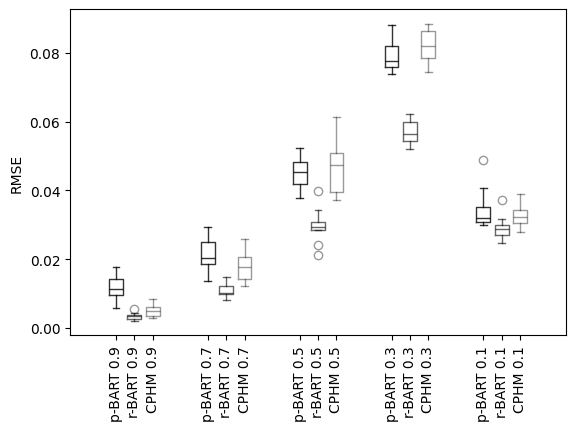

In [613]:
for i in [.9, .7, .5, .3, .1]:
    tmp = n4000[n4000["deciles"]== i]

    pst = i * 5
    alpha3 = 0.4
    alpha2=0.8
    plt.boxplot(
            tmp["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.6
    plt.boxplot(
            tmp["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.4
    plt.boxplot(
            tmp["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # lbls = [str(i) for i in [0.1,.2, .3, .4, .5, .6,.7,.8, .9]]
lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]
# pts = np.array([0.9, .7,  .5, .3, .1]) * 5
pts = np.array([0.1, .3,  .5, .7, .9]) * 5
lbls = lbls[::-1]
plt.xticks(
    np.hstack([pts-.2, pts, pts + .2]) ,
    # labels =  ["" + x for x in lbls] + ["R" + x for x in lbls]  + ["C" + x for x in lbls] ,
    labels = ["p-BART " + x for x in lbls] + ["r-BART " + x for x in lbls] + ["CPHM " + x for x in lbls],
    rotation = 90
)
plt.ylabel("RMSE")
plt.subplots_adjust(bottom=0.20)
plt.savefig("../final_figs/ooo_rmse_N_4000.png")

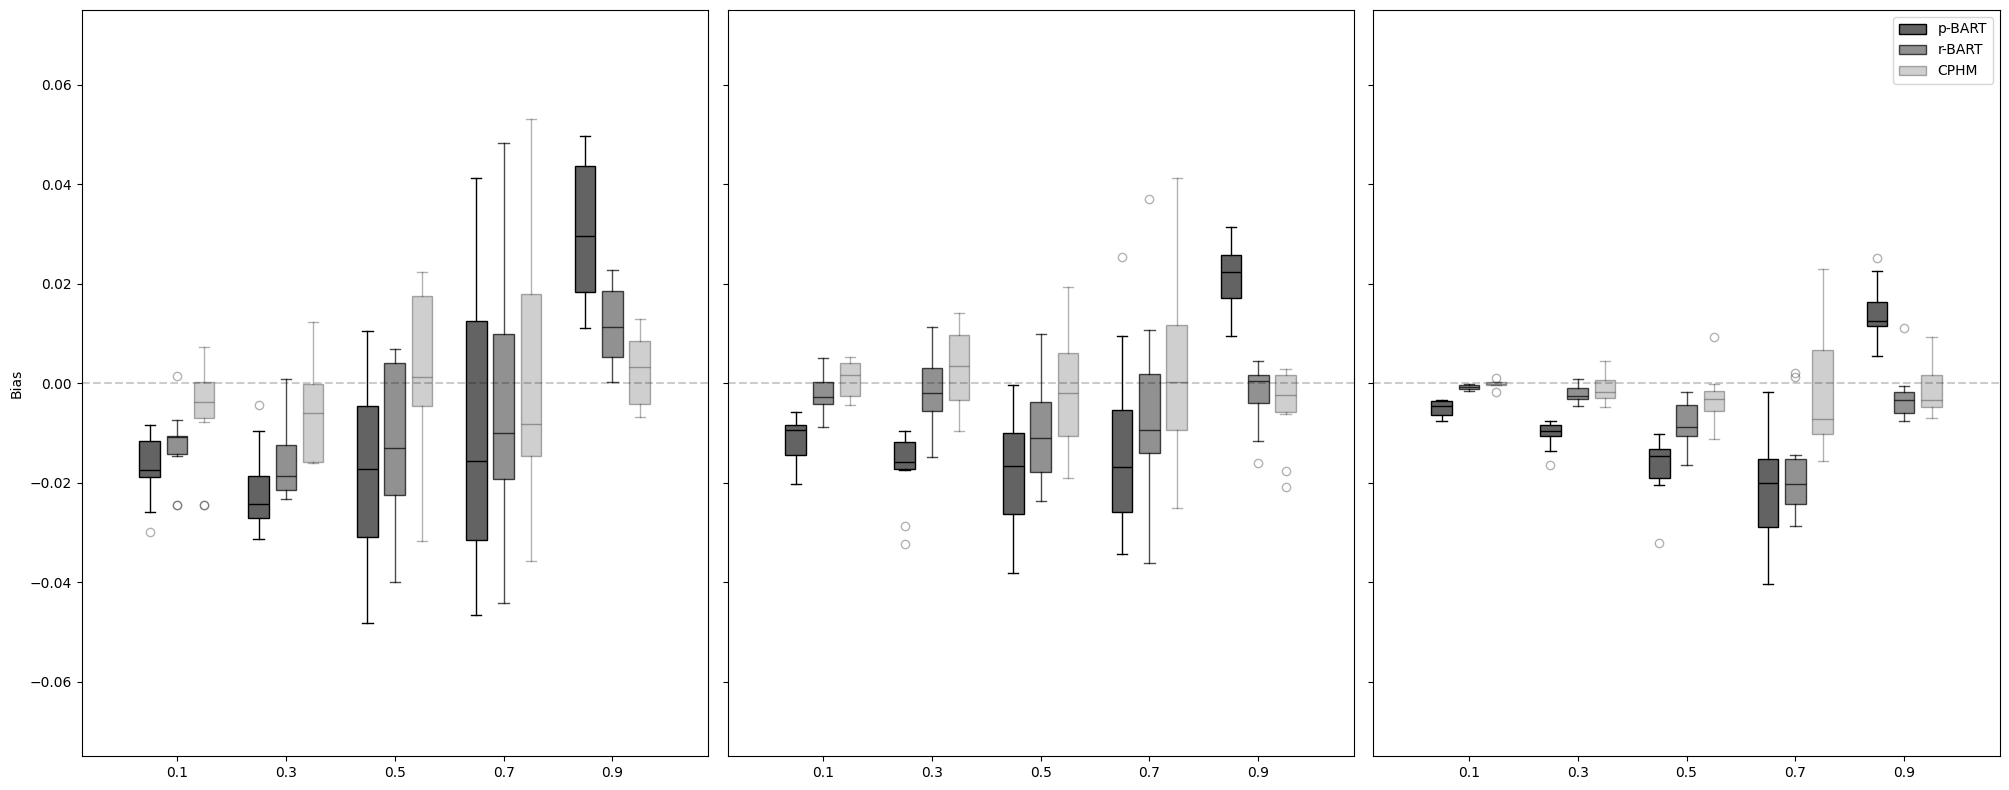

In [24]:
fig,ax = plt.subplots(nrows=1,ncols=3, figsize=(20,8), sharey=True)
scale = 4
for i in [.9, .7, .5, .3, .1]:
    tmp1 = n400[n400["deciles"]== i]
    tmp2 = n1000[n1000["deciles"]== i]
    tmp3 = n4000[n4000["deciles"]== i]

    
    pst = i * scale
    alpha3 = 0.3
    alpha2=1
    ax[0].boxplot(
            tmp1["p_bias"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.7
    ax[0].boxplot(
            tmp1["r_bias"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.3
    ax[0].boxplot(
            tmp1["c_bias"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # 1000
    alpha2=1
    ax[1].boxplot(
            tmp2["p_bias"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.7
    ax[1].boxplot(
            tmp2["r_bias"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.3
    ax[1].boxplot(
            tmp2["c_bias"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    # 4000
    alpha2=1
    ax[2].boxplot(
            tmp3["p_bias"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label='p-BART'if i == 0.1 else None
            )
    alpha2=0.7
    ax[2].boxplot(
            tmp3["r_bias"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="r-BART" if i == 0.1 else None
            )
    alpha2=0.3
    ax[2].boxplot(
            tmp3["c_bias"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="CPHM" if i == 0.1 else None
            )

lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]
pts = np.array([0.1, .3,  .5, .7, .9]) * scale
ax[0].set_xticks(
    pts, lbls
)

ax[1].set_xticks(
    pts,lbls
    
)

ax[2].set_xticks(
    pts,lbls
)
# ax[0].set_ylabel("Bias")
ax[0].set_ylim((-0.075, 0.075))
ax[1].set_ylim((-0.075, 0.075))
ax[2].set_ylim((-0.075, 0.075))
ax[0].axhline(0, linestyle = "--", c="black", alpha=0.2 )
ax[1].axhline(0, linestyle = "--", c="black", alpha=0.2 )
ax[2].axhline(0, linestyle = "--", c="black", alpha=0.2 )
plt.legend()

# ax[0].subplots_adjust(bottom=0.20)
# ax[1].subplots_adjust(bottom=0.20)
# ax[2].subplots_adjust(bottom=0.20)
plt.subplots_adjust(bottom=0.2)
# plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
ax[0].set_ylabel("Bias")
# plt.yticks([0, .05, 0.1, 0.15, 0.2])
# ax[1].set_ylabel()
plt.savefig("../final_figs/2_ooo_bias_comb.png")

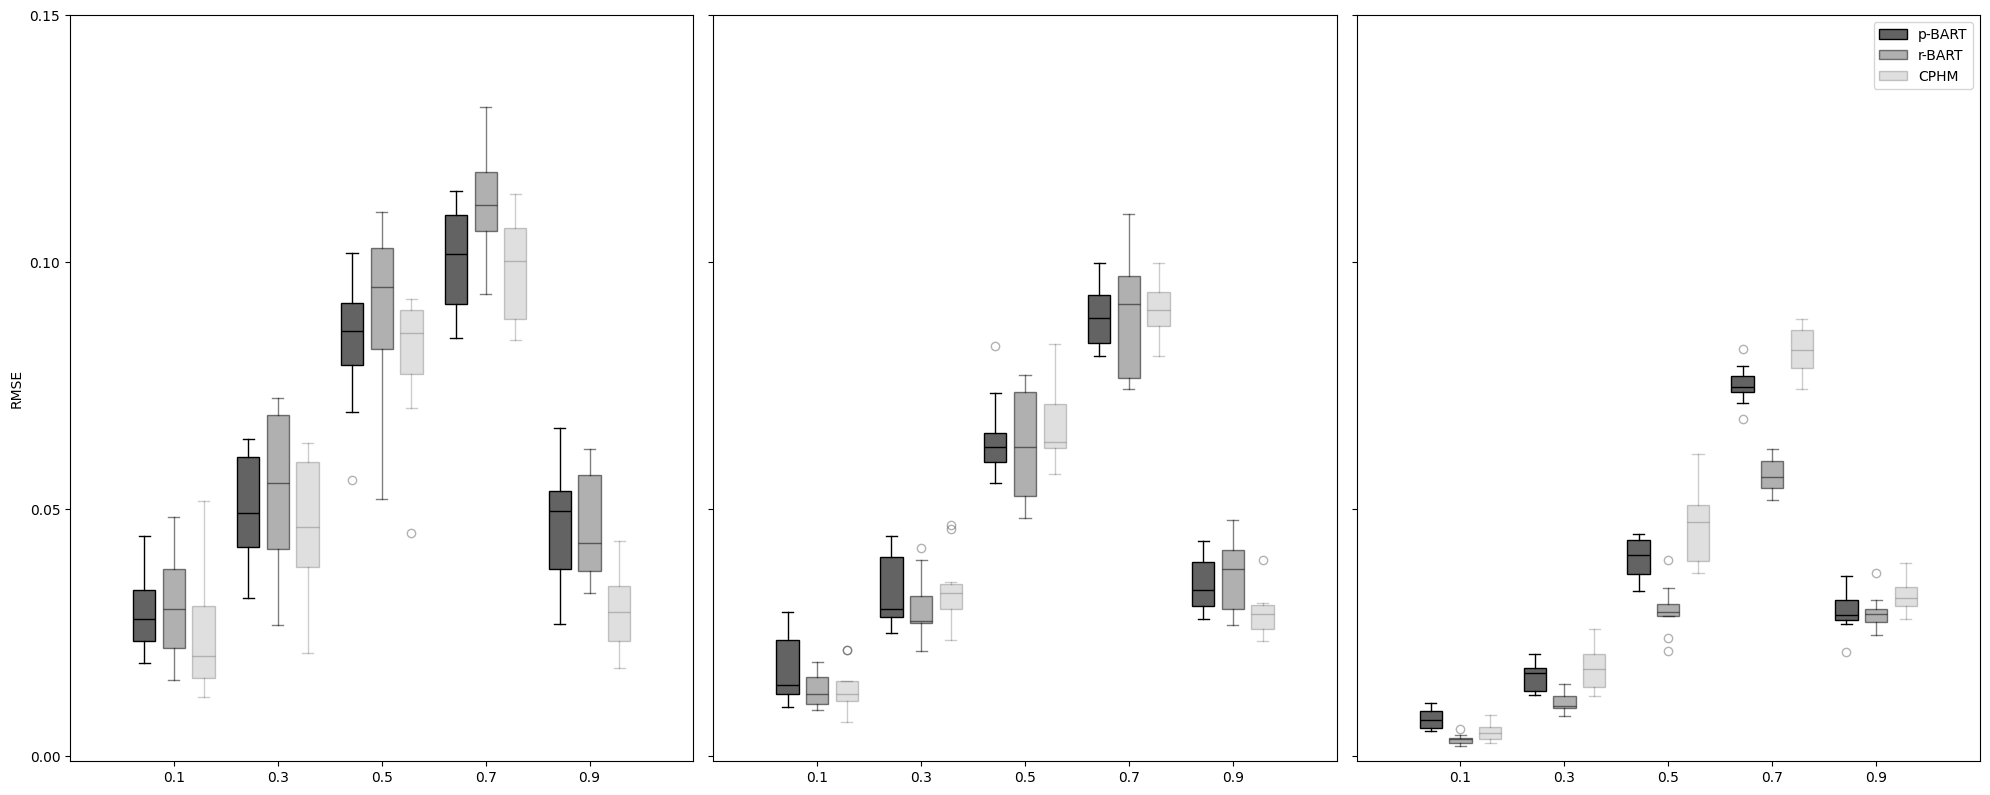

In [21]:
fig,ax = plt.subplots(nrows=1,ncols=3, figsize=(20,8), sharey=True)
scale = 3.5
for i in [.9, .7, .5, .3, .1]:
    tmp1 = n400[n400["deciles"]== i]
    tmp2 = n1000[n1000["deciles"]== i]
    tmp3 = n4000[n4000["deciles"]== i]

    
    pst = i * scale
    alpha3 = 0.3
    alpha2=1
    ax[0].boxplot(
            tmp1["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.5
    ax[0].boxplot(
            tmp1["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.2
    ax[0].boxplot(
            tmp1["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # 1000
    alpha2=1
    ax[1].boxplot(
            tmp2["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.5
    ax[1].boxplot(
            tmp2["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.2
    ax[1].boxplot(
            tmp2["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    # 4000
    alpha2=1
    ax[2].boxplot(
            tmp3["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="p-BART" if i == 0.1 else None
            )
    alpha2=0.5
    ax[2].boxplot(
            tmp3["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="r-BART" if i == 0.1 else None
            )
    alpha2=0.2
    ax[2].boxplot(
            tmp3["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="CPHM" if i == 0.1 else None
            )
    
    
lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]

pts = np.array([0.1, .3,  .5, .7, .9]) * scale

ax[0].set_xticks(
    pts,lbls
)

ax[1].set_xticks(
    pts,lbls
)

ax[2].set_xticks(
    pts, lbls
)
# ax[0].set_ylabel("RMSE")
ax[0].set_ylim((-0.001, 0.15))
ax[1].set_ylim((-0.001, 0.15))
ax[2].set_ylim((-0.001, 0.15))
# ax[0].axhline(0, linestyle = "--", c="black", alpha=0.2 )
# ax[1].axhline(0, linestyle = "--", c="black", alpha=0.2 )
# ax[2].axhline(0, linestyle = "--", c="black", alpha=0.2 )
plt.legend()

ax[0].set_ylabel("RMSE")
# ax[0].subplots_adjust(bottom=0.20)
# ax[1].subplots_adjust(bottom=0.20)
# ax[2].subplots_adjust(bottom=0.20)
plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
plt.yticks([0, .05, 0.1, 0.15])
# ax[1].set_ylabel()
plt.savefig("../final_figs/2_ooo_rmse_comb.png")

In [26]:
print(0.926 - 0.914)
print(0.926 - 0.91)

# max([0.856, 0.878, 0.896]) - 0.856a
print(0.896 - 0.856)
print(0.878 - 0.856)



0.01200000000000001
0.016000000000000014
0.040000000000000036
0.02200000000000002
